
# EDA – Bike Sharing Dataset

## Problemformulering

Hvordan kan historiske data om cykeludlejning analyseres for at finde mønstre og sammenhænge, og hvordan kan Machine Learning bruges til at forudsige antallet af cykeludlejninger ud fra blandt andet vejr, tidspunkt og årstid?

## Introduktion

I denne notebook undersøges Bike Sharing-datasættet fra UCI Machine Learning Repository. Datasættet indeholder oplysninger om cykeludlejning i Washington D.C. fra 2011 til 2012.

Først undersøges datakvaliteten og fordelingen af data. Derefter analyseres outliers og sammenhænge mellem de forskellige variabler.

Arbejdet tager udgangspunkt i CRISP-DM, hvor denne notebook primært omhandler Data Understanding og Data Preparation.

**Datakilde:** [UCI Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)



## 1. Biblioteker og data

De nødvendige Python-biblioteker importeres, og datasættet indlæses med Pandas.


In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True})

DATA_DIR = Path('data')
csv_path = DATA_DIR / 'hour.csv'

df = pd.read_csv(csv_path, parse_dates=['dteday'], sep=',')

print('Datasættets størrelse:', df.shape)
display(df.head())

Datasættets størrelse: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1



## 2. Forstå datasættet

Datasættet indeholder oplysninger om cykeludlejning fordelt på timer. Hver række repræsenterer én time.

Målvariablen er `cnt`, som viser det samlede antal cykeludlejninger i den pågældende time.

Datasættet indeholder også oplysninger om blandt andet temperatur, vejrforhold, tidspunkt og årstid.

Variablerne `casual` og `registered` udgør tilsammen `cnt`. De skal derfor ikke bruges som input i Machine Learning-modellen, da det vil medføre data leakage.


In [2]:
df.info()
display(df.describe(include='all').T)
print('Antal unikke værdier pr. kolonne:')
display(df.nunique().sort_values())

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

,count,mean,min,25%,50%,75%,max,std
instant,17379.0,8690.0,1.0,4345.5,8690.0,13034.5,17379.0,5017.0295
dteday,17379,2012-01-02 04:08:34.552045,2011-01-01 00:00:00,2011-07-04 00:00:00,2012-01-02 00:00:00,2012-07-02 00:00:00,2012-12-31 00:00:00,NaN
season,17379.0,2.50164,1.0,2.0,3.0,3.0,4.0,1.106918
yr,17379.0,0.502561,0.0,0.0,1.0,1.0,1.0,0.500008
mnth,17379.0,6.537775,1.0,4.0,7.0,10.0,12.0,3.438776
hr,17379.0,11.546752,0.0,6.0,12.0,18.0,23.0,6.914405
holiday,17379.0,0.02877,0.0,0.0,0.0,0.0,1.0,0.167165
weekday,17379.0,3.003683,0.0,1.0,3.0,5.0,6.0,2.005771
workingday,17379.0,0.682721,0.0,0.0,1.0,1.0,1.0,0.465431
weathersit,17379.0,1.425283,1.0,1.0,1.0,2.0,4.0,0.639357


Antal unikke værdier pr. kolonne:


yr                2
holiday           2
workingday        2
season            4
weathersit        4
weekday           7
mnth             12
hr               24
windspeed        30
temp             50
atemp            65
hum              89
casual          322
dteday          731
registered      776
cnt             869
instant       17379
dtype: int64


## 3. Datakvalitet

Datasættet undersøges for manglende værdier, dubletter og gentagne registreringer af dato og time.


In [3]:
missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame('Manglende værdier'))
print('Fulde dubletter:', df.duplicated().sum())
print('Gentaget dato + time:', df.duplicated(subset=['dteday', 'hr']).sum())
print('Antal observationer:', len(df))
print('Kontrol af målvariabel: alle casual + registered = cnt:',
      bool((df['casual'] + df['registered'] == df['cnt']).all()))

,Manglende værdier
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


Fulde dubletter: 0
Gentaget dato + time: 0
Antal observationer: 17379
Kontrol af målvariabel: alle casual + registered = cnt: True



### Resultat

Datasættet indeholder 17.379 observationer og 17 variabler.

Der er ingen manglende værdier, dubletter eller gentagne registreringer af dato og time. Der er derfor ikke behov for at fjerne observationer på baggrund af disse kontroller.

Det er også kontrolleret, at `casual + registered = cnt` for alle observationer.




## 4. Datadistribution

Her undersøges fordelingen af antallet af cykeludlejninger (`cnt`) ved hjælp af histogram, boxplot og beskrivende statistik.



Gennemsnit: 189.46
Median: 142.0
Standardafvigelse: 181.39
Skewness (skævhed): 1.28


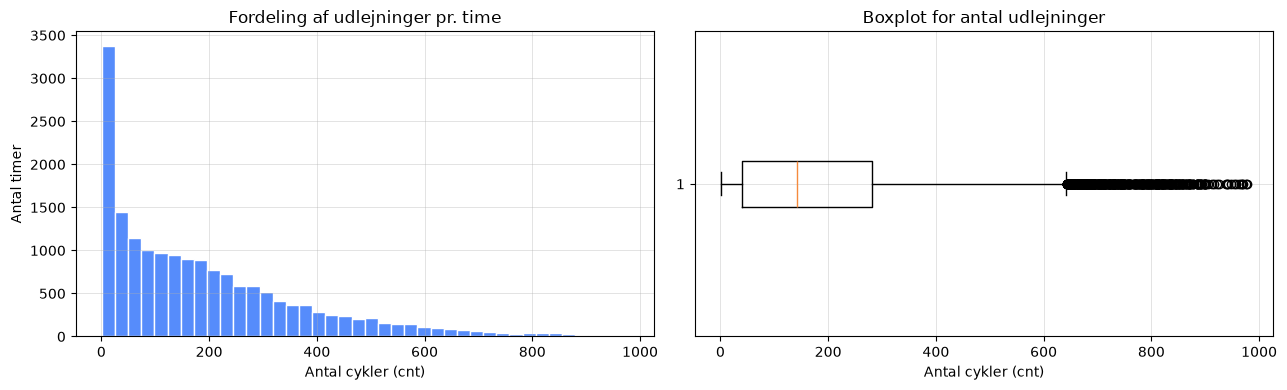

In [5]:
print('Gennemsnit:', round(df['cnt'].mean(), 2))
print('Median:', df['cnt'].median())
print('Standardafvigelse:', round(df['cnt'].std(), 2))
print('Skewness (skævhed):', round(df['cnt'].skew(), 2))
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].hist(df['cnt'], bins=40, edgecolor='white')
axs[0].set(title='Fordeling af udlejninger pr. time', xlabel='Antal cykler (cnt)', ylabel='Antal timer')
axs[1].boxplot(df['cnt'], orientation='horizontal')
axs[1].set(title='Boxplot for antal udlejninger', xlabel='Antal cykler (cnt)')
plt.tight_layout(); plt.show()


### Resultat

Histogrammet viser, at cykeludlejningen er højreskævt fordelt. De fleste timer har relativt få udlejninger, mens enkelte timer har meget høje udlejningstal.

Gennemsnittet er 189,46, mens medianen er 142. Skewness er 1,28, hvilket også viser, at fordelingen er positivt skæv.

Boxplottet viser flere ekstreme værdier, som undersøges nærmere i næste afsnit.



## 5. Outliers med IQR og Z-score

Outliers undersøges med to metoder:

- **IQR:** Bruger kvartilerne og afstanden mellem dem til at identificere ekstreme værdier.
- **Z-score:** Undersøger hvor mange standardafvigelser en værdi ligger fra gennemsnittet.

De to metoder sammenlignes for at se, om de identificerer de samme observationer.


In [6]:
q1, q3 = df['cnt'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
iqr_outliers = (df['cnt'] < lower) | (df['cnt'] > upper)
std = df['cnt'].std(ddof=0)
z_score = (df['cnt'] - df['cnt'].mean()) / std if std else pd.Series(0., index=df.index)
z_outliers = z_score.abs() > 3
print(f'IQR-grænser: {lower:.2f} til {upper:.2f}')
print('Antal outliers (IQR):', int(iqr_outliers.sum()))
print('Antal outliers (Z-score):', int(z_outliers.sum()))
print('Udpeget af begge metoder:', int((iqr_outliers & z_outliers).sum()))
display(df.loc[iqr_outliers | z_outliers, ['dteday','hr','cnt','season','workingday']].head(10))

IQR-grænser: -321.50 til 642.50
Antal outliers (IQR): 505
Antal outliers (Z-score): 244
Udpeget af begge metoder: 244


,dteday,hr,cnt,season,workingday
5536,2011-08-23,14,651,3,1
10358,2012-03-12,17,644,1,1
10359,2012-03-12,18,712,1,1
10382,2012-03-13,17,676,1,1
10383,2012-03-13,18,734,1,1
10397,2012-03-14,8,662,1,1
10406,2012-03-14,17,782,1,1
10407,2012-03-14,18,749,1,1
10430,2012-03-15,17,713,1,1
10431,2012-03-15,18,746,1,1



### Resultat

IQR-metoden identificerede 505 outliers, mens Z-score identificerede 244. Alle 244 observationer fra Z-score blev også identificeret med IQR.

Forskellen skyldes, at metoderne anvender forskellige grænser for ekstreme værdier.

Flere af de høje udlejningstal ligger omkring myldretiden. Derfor beholdes observationerne, da de kan være reelle og relevante for modellens forudsigelser.



## 6. Cykeludlejning fordelt på tid og årstid

Her undersøges det gennemsnitlige antal cykeludlejninger fordelt på klokkeslæt, ugedag og årstid.


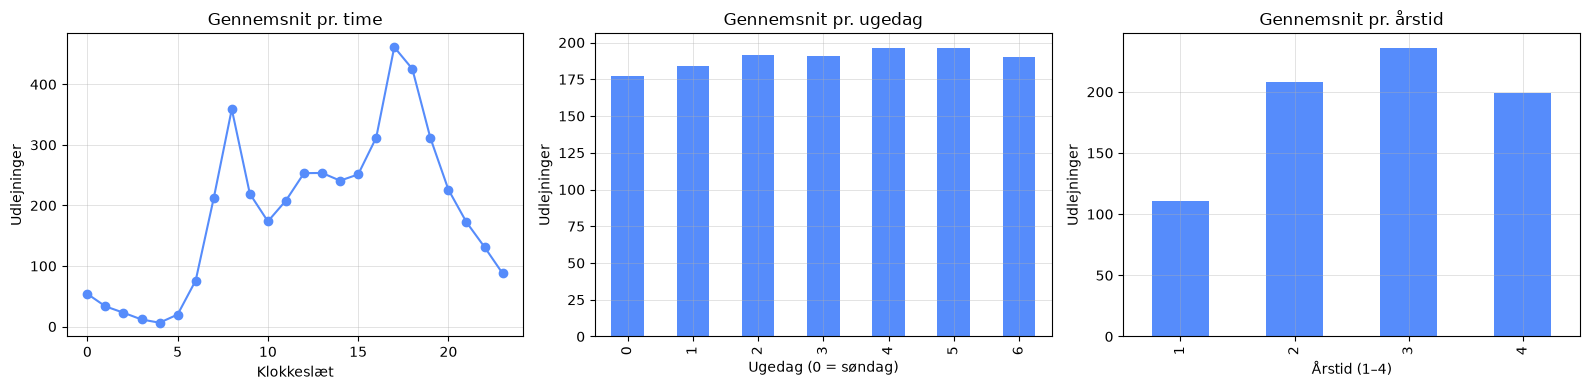

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
df.groupby('hr')['cnt'].mean().plot(ax=axs[0], marker='o')
axs[0].set(title='Gennemsnit pr. time', xlabel='Klokkeslæt', ylabel='Udlejninger')
df.groupby('weekday')['cnt'].mean().plot(kind='bar', ax=axs[1])
axs[1].set(title='Gennemsnit pr. ugedag', xlabel='Ugedag (0 = søndag)', ylabel='Udlejninger')
df.groupby('season')['cnt'].mean().plot(kind='bar', ax=axs[2])
axs[2].set(title='Gennemsnit pr. årstid', xlabel='Årstid (1–4)', ylabel='Udlejninger')
plt.tight_layout();plt.show()


### Resultat

Der er tydelige forskelle i cykeludlejningen gennem døgnet. Aktiviteten er lav om natten og stiger især omkring kl. 8 og kl. 17-18.

Fordelingen på ugedage er mere jævn, mens der ses større forskelle mellem årstiderne.

Resultaterne tyder på, at særligt tidspunkt og årstid kan være relevante for Machine Learning-modellen.



## 7. Vejr og cykeludlejning

Sammenhængen mellem temperatur, vejrforhold og antallet af cykeludlejninger undersøges.


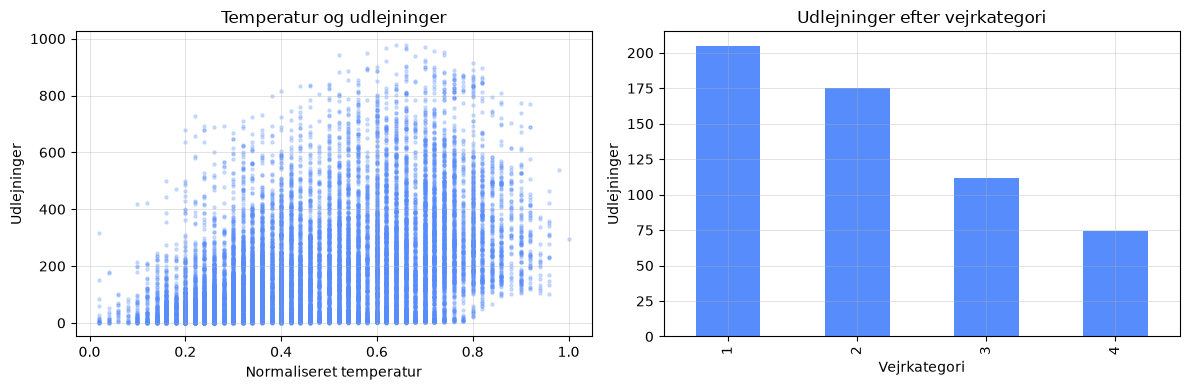

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].scatter(df['temp'], df['cnt'], s=5, alpha=.25)
axs[0].set(title='Temperatur og udlejninger', xlabel='Normaliseret temperatur', ylabel='Udlejninger')
df.groupby('weathersit')['cnt'].mean().plot(kind='bar', ax=axs[1])
axs[1].set(title='Udlejninger efter vejrkategori', xlabel='Vejrkategori', ylabel='Udlejninger')
plt.tight_layout();plt.show()


### Resultat

Der ses generelt flere cykeludlejninger ved højere temperaturer, mens udlejningen er lavere ved kolde temperaturer.

Antallet af udlejninger falder også generelt ved dårligere vejrforhold.

Der er dog stor variation ved samme temperatur, hvilket viser, at andre faktorer også kan have betydning.



## 8. Korrelationsanalyse

Pearsons korrelation bruges til at undersøge lineære sammenhænge mellem udvalgte numeriske variabler.

Korrelationen ligger mellem -1 og 1, hvor positive værdier viser en positiv sammenhæng og negative værdier en negativ sammenhæng.


,cnt,temp,atemp,hum,windspeed,hr
cnt,1.00,0.40,0.40,-0.32,0.09,0.39
temp,0.40,1.00,0.99,-0.07,-0.02,0.14
atemp,0.40,0.99,1.00,-0.05,-0.06,0.13
hum,-0.32,-0.07,-0.05,1.00,-0.29,-0.28
windspeed,0.09,-0.02,-0.06,-0.29,1.00,0.14
hr,0.39,0.14,0.13,-0.28,0.14,1.00


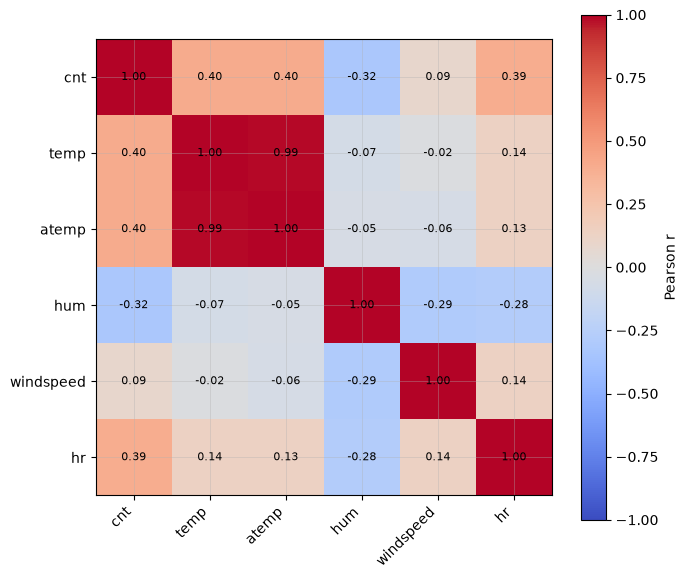

In [9]:
numeric = ['cnt', 'temp', 'atemp', 'hum', 'windspeed', 'hr']
corr = df[numeric].corr()
display(corr.round(2))
fig, ax = plt.subplots(figsize=(7, 6))
im=ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(numeric)),numeric,rotation=45,ha='right')
ax.set_yticks(range(len(numeric)),numeric)
for i in range(len(numeric)):
    for j in range(len(numeric)):
        ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
fig.colorbar(im, ax=ax, label='Pearson r')
plt.tight_layout();plt.show()


### Resultat

Temperatur og følt temperatur har begge en positiv korrelation på 0,40 med antallet af cykeludlejninger.

Luftfugtighed har en negativ korrelation på -0,32, mens vindhastighed har en svag korrelation på 0,09.

Der ses desuden en meget stærk korrelation på 0,99 mellem `temp` og `atemp`, hvilket betyder, at de indeholder næsten den samme information.

Resultaterne er relevante ved udvælgelsen af features til modellen. Korrelation viser dog ikke nødvendigvis en årsagssammenhæng.


## 9. Sammenligning af arbejdsdage og fridage

Den tidligere analyse viste høj aktivitet omkring kl. 8 og kl. 17-18.

Her undersøges det, om mønsteret er forskelligt på arbejdsdage og fridage.

Hypotesen er, at arbejdsdage har tydelige aktivitetstoppe på grund af pendling, mens fridage har en mere jævn fordeling gennem dagen.

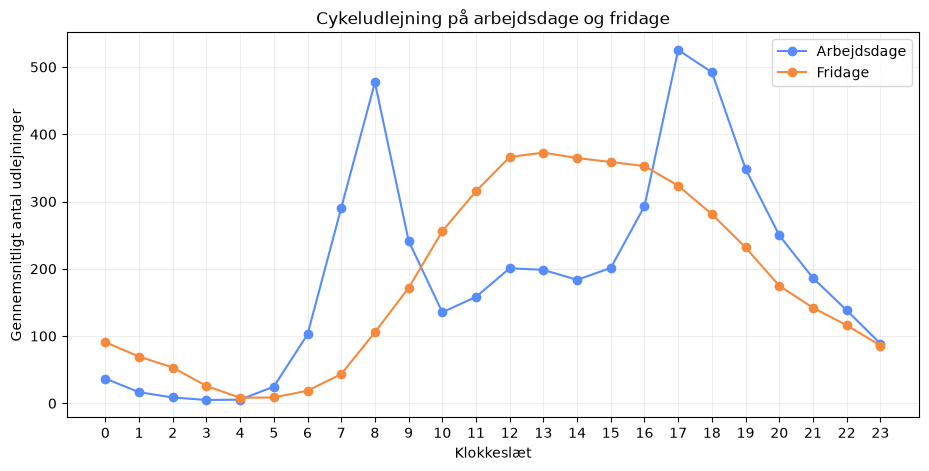

In [10]:
# Gennemsnitlige cykeludlejninger fordelt på time og dagstype
hourly_comparison = (
    df.groupby(['hr', 'workingday'])['cnt']
    .mean()
    .unstack()
)

plt.figure(figsize=(11, 5))

plt.plot(
    hourly_comparison.index,
    hourly_comparison[1],
    marker='o',
    label='Arbejdsdage'
)

plt.plot(
    hourly_comparison.index,
    hourly_comparison[0],
    marker='o',
    label='Fridage'
)

plt.title('Cykeludlejning på arbejdsdage og fridage')
plt.xlabel('Klokkeslæt')
plt.ylabel('Gennemsnitligt antal udlejninger')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(alpha=0.3)

plt.show()


### Resultat

Grafen viser to tydelige aktivitetstoppe på arbejdsdage omkring kl. 8 og kl. 17.

På fridage er udlejningen derimod mere jævnt fordelt over dagtimerne med den højeste aktivitet omkring middag og eftermiddag.

Resultaterne understøtter hypotesen om forskellige udlejningsmønstre på arbejdsdage og fridage.

Dette bruges senere til at udvikle en ny feature i Machine Learning-modellen.



## 10. Forberedelse til Modeling

Resultaterne fra EDA bruges som grundlag for den efterfølgende modeludvikling.

Målvariablen er `cnt`, mens blandt andet tidspunkt, temperatur, vejr og arbejdsdage anvendes som input.

`casual` og `registered` udelades for at undgå data leakage.

Data opdeles kronologisk, så modellen trænes på tidligere observationer og testes på senere observationer.



## 11. Konklusion

EDA-analysen viser, at antallet af cykeludlejninger varierer meget afhængigt af tidspunkt, temperatur, vejr og årstid.

Datasættet indeholder ingen manglende værdier eller dubletter. Fordelingen af cykeludlejninger er højreskæv, og der er identificeret outliers med både IQR og Z-score.

Der er særligt tydelige forskelle mellem arbejdsdage og fridage. På arbejdsdage ses høj aktivitet i myldretiden, mens udlejningen på fridage er mere jævnt fordelt.

Resultaterne bruges i Modeling til at vælge relevante features og undersøge, hvor præcist antallet af cykeludlejninger kan forudsiges.
